In [1]:
from astropy.io import fits
from astropy.wcs import WCS
import matplotlib.pyplot as plt
from astropy.stats import sigma_clipped_stats
from astropy.visualization import SinhStretch
import numpy as np
from photutils.detection import DAOStarFinder
import glob
from astropy.visualization.mpl_normalize import ImageNormalize
from photutils.aperture import CircularAperture

# Ein Frame

In [2]:
hdu = fits.open('20240715_science/long/20240715T201938.0.pico.object.science.fits')  

data = hdu[0].data  
header = hdu[0].header
j_date = header['MJD-OBS']
print(header['EXPTIME'])
print(header['MJD-OBS'])

mean, median, std = sigma_clipped_stats(data, sigma=3.0)  
print(np.array((mean, median, std)))  
print('estimated background:', median)
print('detection threshold:', 5*std)

30.0
60506.8469675926


[70.37555247 69.89753133 14.39755575]
estimated background: 69.89753133496916
detection threshold: 71.98777876045453


(1510.0, 1580.0)

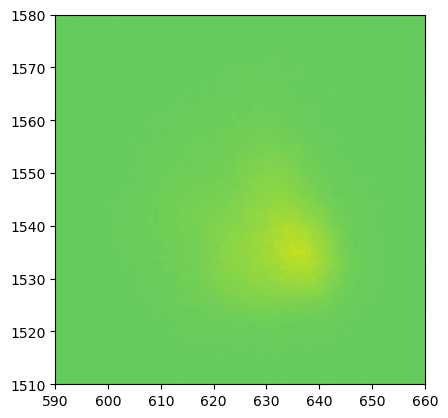

In [3]:
plt.imshow(data)
plt.xlim(590, 660)
plt.ylim(1510, 1580)

22.202796349616904 2046.2037804662523


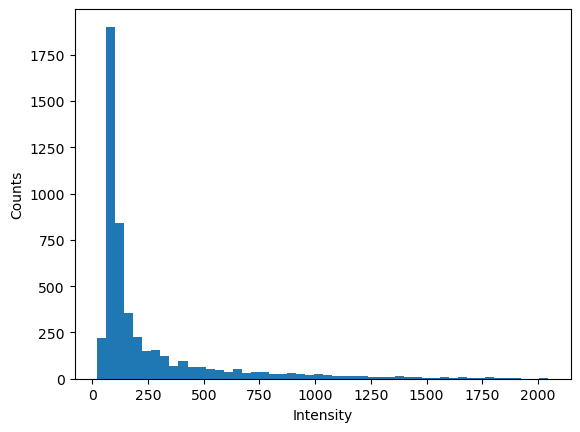

In [4]:
cutout = data[1510:1580, 590:660]  # note: numpy is [y, x]
print(cutout.min(), cutout.max())
plt.hist(cutout.flatten(), bins=50)
plt.ylabel('Counts')
plt.xlabel('Intensity')
plt.show()

In [5]:
daofind = DAOStarFinder(fwhm=30, threshold=5*std)  
sources = daofind(data - median)  
for col in sources.colnames:  
    if col not in ('id', 'npix'):
        sources[col].info.format = '%.2f'  # for consistent table output
sources.pprint(max_width=106) 

 id xcentroid ycentroid sharpness roundness1 roundness2 npix  peak    flux    mag   daofind_mag
--- --------- --------- --------- ---------- ---------- ---- ------ -------- ------ -----------
  1   1702.99      7.43      0.65      -0.22      -0.15 1521  44.26 12301.44 -10.22       -1.71
  2    993.93      9.86      0.58      -0.23      -0.10 1521 171.43 59943.64 -11.94       -3.21
  3    432.78     16.27      0.64      -0.23       0.07 1521  38.65 13977.99 -10.36       -1.49
  4    783.22     26.26      0.92      -0.38      -0.35 1521  24.16  5842.24  -9.42       -0.73
  5   1798.79     48.10      0.93      -0.00       0.35 1521  12.38  1480.57  -7.93       -0.06
  6   1115.30    147.55      0.54       0.30       0.07 1521  11.00  6949.57  -9.60       -0.06
  7    258.25    206.77      0.33      -0.15       0.01 1521  16.14  9459.24  -9.94       -0.94
  8   1302.86    247.72      0.71       0.04      -0.06 1521  33.61 11778.23 -10.18       -1.24
  9    376.99    257.03      0.87      -

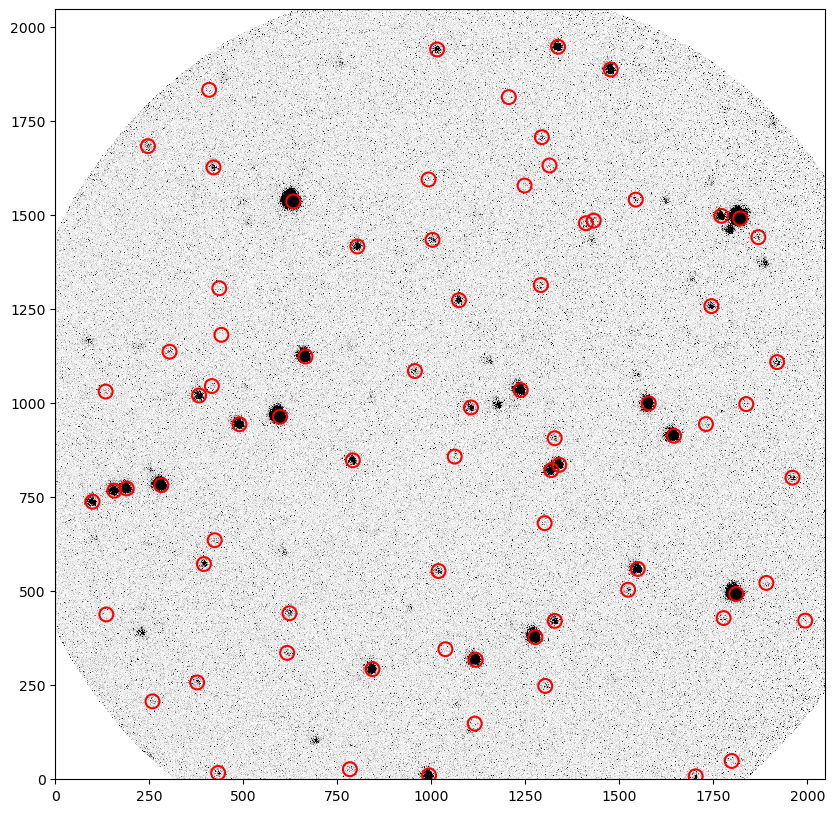

In [6]:
#positions = np.transpose((sources['xcentroid'], sources['ycentroid']))
#apertures = CircularAperture(positions, r=20.0)
norm = ImageNormalize(stretch=SinhStretch())

upper_limit = np.percentile(data[np.isfinite(data)], 99)
lower_limit = np.percentile(data[np.isfinite(data)], 1)
data = np.clip(data, None, upper_limit)
data = np.clip(data, lower_limit, None)

fig = plt.figure(figsize=(10, 10))
plt.imshow(data, cmap='Greys', origin='lower', norm=norm, interpolation='nearest')
#apertures.plot(color='red', lw=1.5, alpha=1)
plt.scatter(sources['xcentroid'], sources['ycentroid'], s=100, edgecolor='red', facecolor='none', lw=1.5, alpha=1)
plt.show()

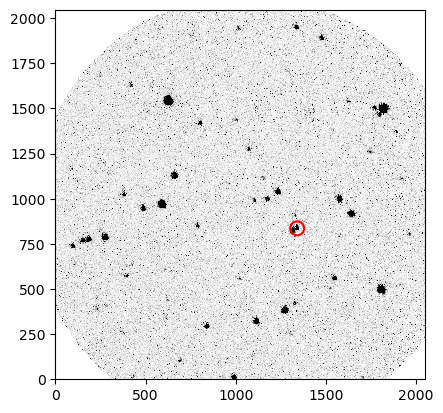

In [7]:
plt.imshow(data, cmap='Greys', origin='lower', norm=norm, interpolation='nearest')
plt.scatter(sources['xcentroid'][33], sources['ycentroid'][33], s=100, edgecolor='red', facecolor='none', lw=1.5, alpha=1)
plt.show()

In [8]:
print(sources['xcentroid'][32], sources['ycentroid'][32], sources['flux'][32])

1318.873496398079 821.6128307907776 67812.76689476633


In [9]:
x0, y0 = sources['xcentroid'][32], sources['ycentroid'][32]
tol = 2.0
flux_array = []

for l in [sources]:  # assume list of tables/arrays
    dx = l['xcentroid'] - x0
    dy = l['ycentroid'] - y0
    dist = np.sqrt(dx**2 + dy**2)
    
    idx = np.where(dist < tol)[0][0]
    flux = l['flux'][idx]
    flux_array.append(flux)
    print(flux)

67812.76689476633


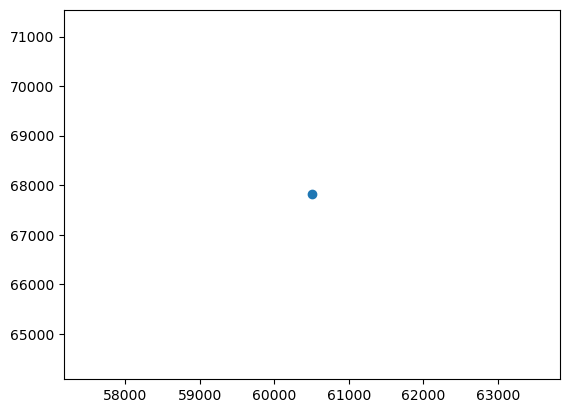

In [10]:
plt.scatter(j_date, flux_array )

# Cubes

(2048, 2048)


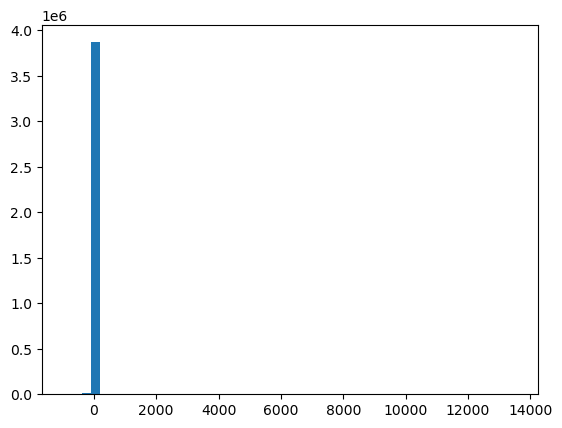

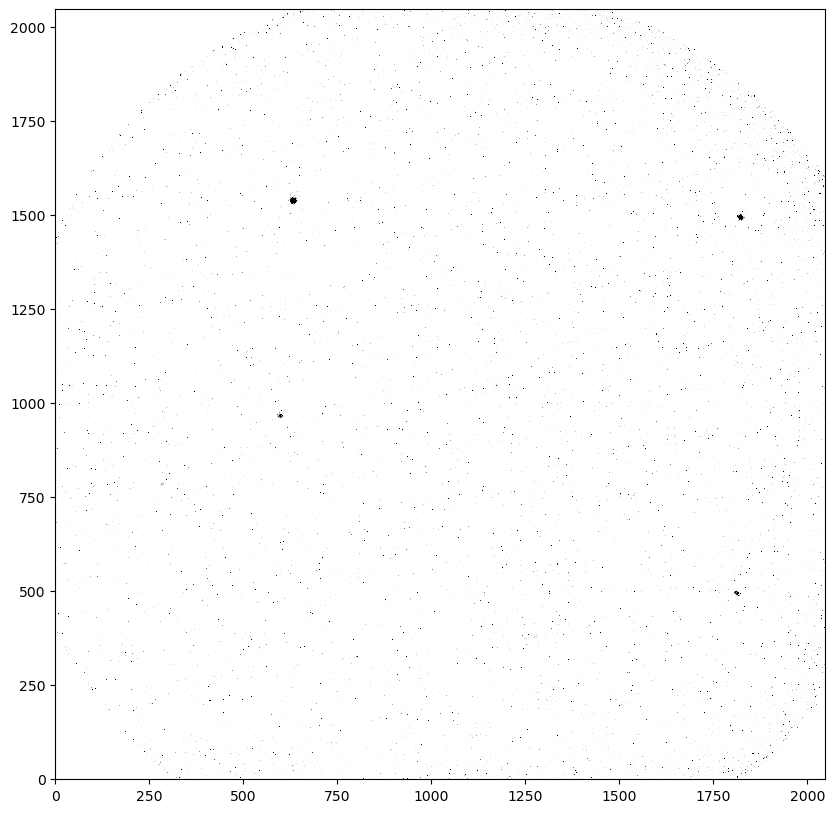

In [15]:
with fits.open('20240715_science/20240715T220826.0.pico.object.science.fits') as hdu:
    data = hdu[0].data

data = np.sum(data, axis=0)  # sum over time axis
print(data.shape)
plt.hist(data.flatten(), bins=50)
#plt.imshow(data, cmap='Greys', origin='lower', norm=norm, interpolation='nearest')
'''
upper_limit = np.percentile(data[np.isfinite(data)], 99)
lower_limit = np.percentile(data[np.isfinite(data)], 1)
data = np.clip(data, None, upper_limit)
data = np.clip(data, lower_limit, None)'''

fig = plt.figure(figsize=(10, 10))
plt.imshow(data, cmap='Greys', origin='lower', norm=norm, interpolation='nearest')
#apertures.plot(color='red', lw=1.5, alpha=1)
#plt.scatter(sources['xcentroid'], sources['ycentroid'], s=100, edgecolor='red', facecolor='none', lw=1.5, alpha=1)
plt.show()



In [ ]:
for slice_data in data:
    
    mean, median, std = sigma_clipped_stats(slice_data, sigma=3.0)
    print(mean, median, std)
    daofind = DAOStarFinder(fwhm=30, threshold=5 * std)
    sources = daofind(slice_data - median)

'''    if sources is None:
        continue

    for col in sources.colnames:
        if col not in ('id', 'npix'):
            sources[col].info.format = '%.2f'

    dx = sources['xcentroid'] - x0
    dy = sources['ycentroid'] - y0
    dist = np.sqrt(dx**2 + dy**2)

    if np.any(dist < tol):
        idx = np.where(dist < tol)[0][0]
        flux = sources['flux'][idx]
        flux_array.append(flux)'''

# Alle Frames

In [14]:
x0, y0 = sources['xcentroid'][32], sources['ycentroid'][32]
tol = 2.0
flux_array = []

files = glob.glob("20240715_science/long/*.object.science.fits")

for fname in files:
    with fits.open(fname) as hdu:
        data = hdu[0].data
    
    slices = [data]
    # --- distinguish 2D vs 3D ---
    '''    if data.ndim == 2:
        slices = [data]
    elif data.ndim == 3:
        slices = data, axis=0
    else:
        continue'''

    for slice_data in slices:
        mean, median, std = sigma_clipped_stats(slice_data, sigma=3.0)

        daofind = DAOStarFinder(fwhm=30, threshold=5 * std)
        sources = daofind(slice_data - median)

        if sources is None:
            continue

        for col in sources.colnames:
            if col not in ('id', 'npix'):
                sources[col].info.format = '%.2f'

        dx = sources['xcentroid'] - x0
        dy = sources['ycentroid'] - y0
        dist = np.sqrt(dx**2 + dy**2)

        if np.any(dist < tol):
            idx = np.where(dist < tol)[0][0]
            flux = sources['flux'][idx]
            flux_array.append(flux)

[-856.727524835844]


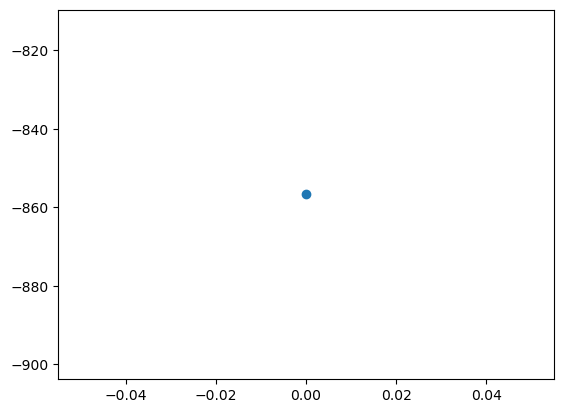

In [15]:
print(flux_array)

x = np.linspace(0, len(flux_array)-1, len(flux_array))  # or use actual time values if available
plt.scatter(x, flux_array)